# Co-workership network from `people.csv`

Two people are **connected** when they appear on the same dataset (one dataset = one `_source_file`).
Edge weight = number of datasets they share. Two graphs are built:

- **Co-author graph**: both are authors of the same dataset
- **Collaboration graph**: both appear on the same dataset in any role (author or contributor)

Input: `data/people.csv` in the repository root, produced by `authors_contributors.ipynb`.
All outputs (`coworker_edges.csv`, `coworkers.gexf`, `coworkers.html`) are written to the same `data/` directory.

In [1]:
import html
from collections import defaultdict
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import HTML, display
from networkx.algorithms.community import greedy_modularity_communities
from pyvis.network import Network

# Notebook lives in src/exploring/json-metadata/, so the repo root is 3 levels up
DATA_DIR = Path("../../../data").resolve()
CSV_PATH = DATA_DIR / "people.csv"
MAX_PEOPLE_PER_DATASET = 50   # datasets with more people are skipped (pairs grow quadratically)

## 1. Load and clean

In [2]:
df = pd.read_csv(CSV_PATH)
df = df.dropna(subset=["name"]).copy()
df["name"] = df["name"].astype(str).str.strip()

# Identity key: lowercase, collapsed whitespace. Spelling variants of the same
# person ("Doe, J." vs "Doe, Jane") will NOT be merged; see the note at the end.
df["key"] = df["name"].str.lower().str.replace(r"\s+", " ", regex=True)

# One person counts once per dataset, even if listed twice or as author AND contributor.
# If they are an author on that dataset, keep that flag.
per_ds = (df.groupby(["_source_file", "key"], as_index=False)
            .agg(isAuthor=("isAuthor", "max")))

print(f"{len(df)} rows -> {len(per_ds)} unique (dataset, person) pairs")
print(f"{df.key.nunique()} unique people, {df._source_file.nunique()} datasets")

23416 rows -> 23124 unique (dataset, person) pairs
9995 unique people, 9544 datasets


## 2. Build the graphs

In [3]:
# Node attributes: display name, most common affiliation, number of datasets
display_name = df.groupby("key")["name"].agg(lambda s: s.value_counts().index[0])
affil = (df.dropna(subset=["authorAffiliation"])
           .groupby("key")["authorAffiliation"]
           .agg(lambda s: s.value_counts().index[0]))
n_ds = per_ds.groupby("key")["_source_file"].nunique()

edge_datasets = defaultdict(list)   # frozenset({a, b}) -> [dataset files]

def build_graph(only_authors=False):
    d = per_ds[per_ds.isAuthor] if only_authors else per_ds
    G = nx.Graph()
    G.add_nodes_from(
        (k, {"label": display_name[k], "affiliation": affil.get(k, ""), "n_datasets": int(n_ds[k])})
        for k in d["key"].unique()
    )
    skipped = 0
    for ds, grp in d.groupby("_source_file"):
        people = sorted(set(grp["key"]))
        if len(people) > MAX_PEOPLE_PER_DATASET:
            skipped += 1
            continue
        for a, b in combinations(people, 2):
            if G.has_edge(a, b):
                G[a][b]["weight"] += 1
            else:
                G.add_edge(a, b, weight=1)
            if not only_authors:
                edge_datasets[frozenset((a, b))].append(ds)
    print(f"{'Co-author' if only_authors else 'Collaboration'} graph: "
          f"{G.number_of_nodes()} people, {G.number_of_edges()} links, "
          f"{skipped} oversized datasets skipped")
    return G

G_auth = build_graph(only_authors=True)
G_all = build_graph(only_authors=False)

Co-author graph: 9495 people, 25944 links, 1 oversized datasets skipped
Collaboration graph: 9995 people, 28756 links, 1 oversized datasets skipped


## 3. Network statistics

In [4]:
def summarize(G, name, top=10):
    comps = sorted(nx.connected_components(G), key=len, reverse=True)
    print(f"=== {name} ===")
    print(f"People: {G.number_of_nodes()}   Links: {G.number_of_edges()}   "
          f"Density: {nx.density(G):.5f}")
    print(f"Connected components: {len(comps)}   Largest: {len(comps[0])} people "
          f"({len(comps[0]) / G.number_of_nodes():.0%})")
    print(f"Isolated people (no co-workers): {sum(1 for _, d in G.degree() if d == 0)}")

    wdeg = dict(G.degree(weight="weight"))
    print("\nMost connected people (weighted):")
    for k, v in sorted(wdeg.items(), key=lambda x: -x[1])[:top]:
        print(f"  {G.nodes[k]['label']:40} links={G.degree(k):4}  weighted={v}")

    print("\nStrongest pairs:")
    pairs = sorted(G.edges(data=True), key=lambda e: -e[2]["weight"])[:top]
    for a, b, d in pairs:
        print(f"  {G.nodes[a]['label']} <-> {G.nodes[b]['label']}: {d['weight']} datasets")
    print()

summarize(G_auth, "Co-author graph")
summarize(G_all, "Collaboration graph")

=== Co-author graph ===
People: 9495   Links: 25944   Density: 0.00058
Connected components: 2335   Largest: 584 people (6%)
Isolated people (no co-workers): 1378

Most connected people (weighted):
  Esther Jansma                            links=  48  weighted=3417
  Elsemieke Spoor-Hanraets                 links=  20  weighted=2179
  Tamara Vernimmen                         links=   5  weighted=1392
  Marta Domínguez Delmás                   links=  13  weighted=762
  Dieuwertje Duijn                         links=   5  weighted=248
  Benno Ridderhof                          links=   4  weighted=213
  Dirk Jan de Vries                        links=   4  weighted=199
  Evers, Andrea                            links= 118  weighted=198
  Hans Tisje                               links=   3  weighted=197
  Govers, Laura L.                         links=  87  weighted=157

Strongest pairs:
  Esther Jansma <-> Elsemieke Spoor-Hanraets: 1383 datasets
  Esther Jansma <-> Tamara Vernimmen: 697

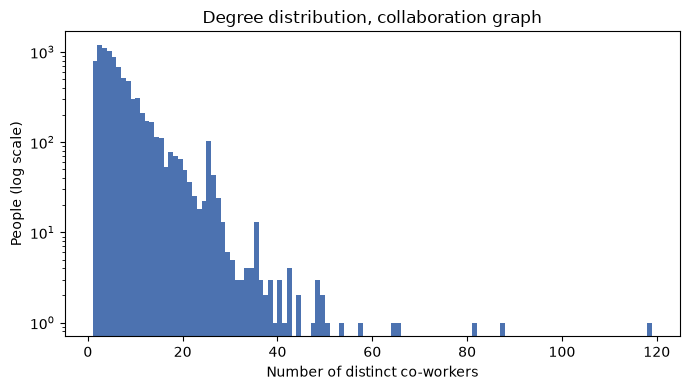

In [5]:
# Degree distribution (log-log style: most people have few links, a few are hubs)
degs = [d for _, d in G_all.degree() if d > 0]
plt.figure(figsize=(7, 4))
plt.hist(degs, bins=range(1, max(degs) + 2), log=True, color="#4C72B0")
plt.xlabel("Number of distinct co-workers")
plt.ylabel("People (log scale)")
plt.title("Degree distribution, collaboration graph")
plt.tight_layout()
plt.show()

## 4. Static visualisation

Node **size** = number of co-workers, node **colour** = detected community (groups of people who work mostly with each other),
edge **thickness** = number of shared datasets. Only the strongest part of the network is drawn so it stays readable.

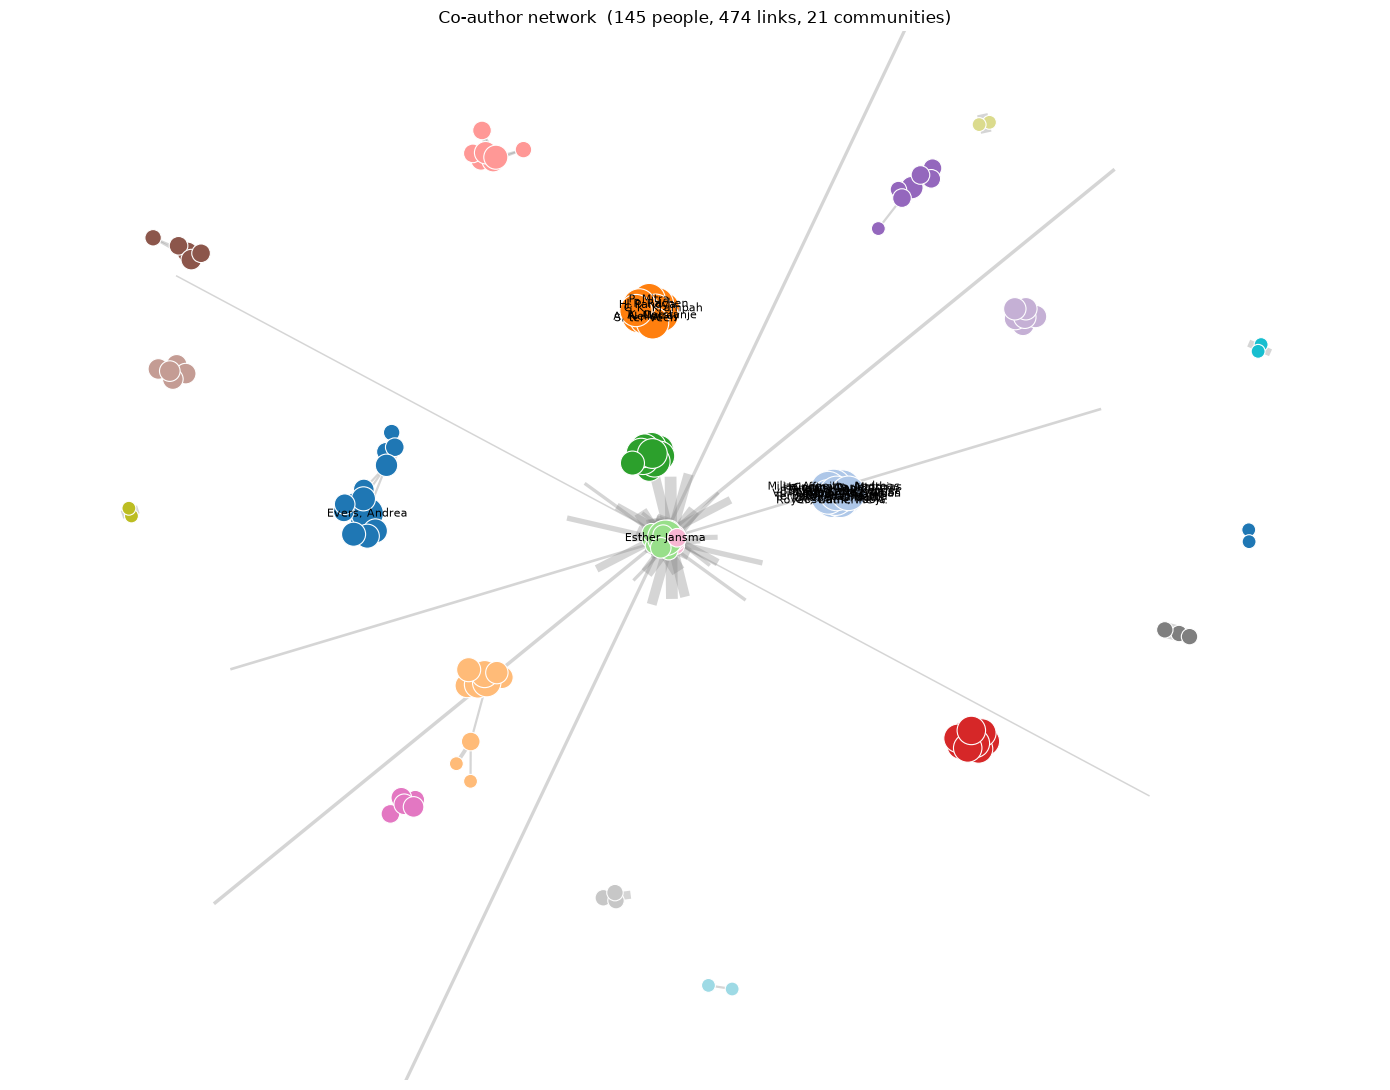

In [7]:
def draw(G, min_weight=1, top_n=150, label_top=25, title="", figsize=(14, 11)):
    H = G.copy()
    H.remove_edges_from([(a, b) for a, b, d in G.edges(data=True) if d["weight"] < min_weight])
    H.remove_nodes_from(list(nx.isolates(H)))

    # keep only the top_n people by weighted degree
    if H.number_of_nodes() > top_n:
        keep = sorted(H.nodes, key=lambda n: -H.degree(n, weight="weight"))[:top_n]
        H = H.subgraph(keep).copy()
        H.remove_nodes_from(list(nx.isolates(H)))
    if H.number_of_nodes() == 0:
        print("Nothing to draw with these filters.")
        return H

    comms = list(greedy_modularity_communities(H, weight="weight"))
    cmap = plt.get_cmap("tab20")
    color = {n: cmap(i % 20) for i, c in enumerate(comms) for n in c}

    pos = nx.spring_layout(H, k=1.2 / (H.number_of_nodes() ** 0.5), seed=42, weight="weight")
    sizes = [60 + 40 * H.degree(n) for n in H]
    widths = [0.4 + 1.2 * H[a][b]["weight"] for a, b in H.edges]

    plt.figure(figsize=figsize)
    nx.draw_networkx_edges(H, pos, width=widths, alpha=0.35, edge_color="#888")
    nx.draw_networkx_nodes(H, pos, node_size=sizes, node_color=[color[n] for n in H],
                           edgecolors="white", linewidths=0.8)
    top = sorted(H.nodes, key=lambda n: -H.degree(n))[:label_top]
    nx.draw_networkx_labels(H, pos, labels={n: H.nodes[n]["label"] for n in top}, font_size=8)
    plt.title(f"{title}  ({H.number_of_nodes()} people, {H.number_of_edges()} links, "
              f"{len(comms)} communities)")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    return H

H1 = draw(G_auth, min_weight=1, top_n=150, title="Co-author network")

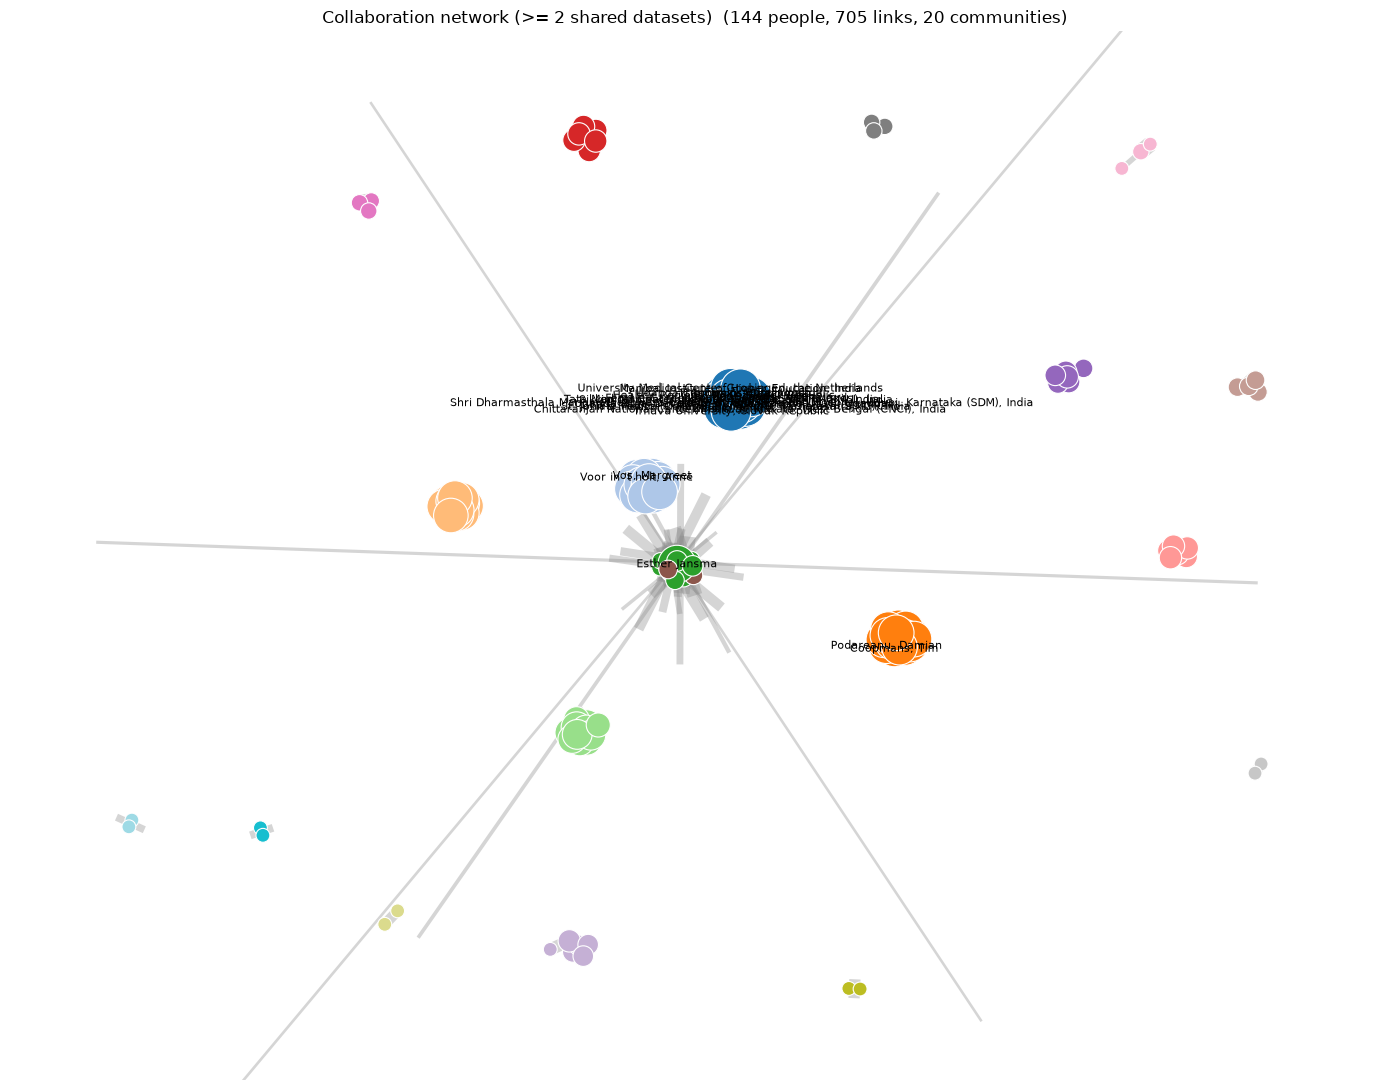

In [8]:
# Collaboration network (any role); a higher min_weight shows only repeated collaborations
H2 = draw(G_all, min_weight=2, top_n=150, title="Collaboration network (>= 2 shared datasets)")

## 5. Zoom in on one person

In [9]:
def find_person(text):
    text = text.lower()
    return [k for k in G_all.nodes if text in k]

def draw_ego(name_fragment, radius=1, graph=G_all):
    matches = [k for k in find_person(name_fragment) if k in graph]
    if not matches:
        print("No match for", name_fragment)
        return
    if len(matches) > 1:
        print("Multiple matches, using the first:", [graph.nodes[m]["label"] for m in matches[:5]])
    center = matches[0]
    E = nx.ego_graph(graph, center, radius=radius)
    pos = nx.spring_layout(E, seed=42, weight="weight")
    plt.figure(figsize=(10, 8))
    nx.draw_networkx_edges(E, pos, width=[0.5 + E[a][b]["weight"] for a, b in E.edges], alpha=0.4)
    nx.draw_networkx_nodes(E, pos, node_size=[300 if n == center else 120 for n in E],
                           node_color=["#C44E52" if n == center else "#4C72B0" for n in E])
    nx.draw_networkx_labels(E, pos, labels={n: E.nodes[n]["label"] for n in E}, font_size=8)
    plt.title(f"Ego network of {graph.nodes[center]['label']} (radius {radius})")
    plt.axis("off")
    plt.show()

# Example: pass part of a name, e.g. draw_ego("doe, jane")
# draw_ego("your name fragment here")

def shared_datasets(name_a, name_b):
    a, b = find_person(name_a)[0], find_person(name_b)[0]
    return edge_datasets.get(frozenset((a, b)), [])

## 6. Interactive graph

Writes `data/coworkers.html` and shows it inline: drag nodes, zoom, hover for details.
The page loads its JavaScript libraries from a CDN, so it needs internet access.

In [11]:
def interactive(G, filename="coworkers.html", min_weight=1, top_n=400):
    H = G.copy()
    H.remove_edges_from([(a, b) for a, b, d in G.edges(data=True) if d["weight"] < min_weight])
    H.remove_nodes_from(list(nx.isolates(H)))
    if H.number_of_nodes() > top_n:
        keep = sorted(H.nodes, key=lambda n: -H.degree(n, weight="weight"))[:top_n]
        H = H.subgraph(keep).copy()
        H.remove_nodes_from(list(nx.isolates(H)))

    comms = list(greedy_modularity_communities(H, weight="weight"))
    group = {n: i for i, c in enumerate(comms) for n in c}

    net = Network(height="750px", width="100%", cdn_resources="remote")
    for n in H:
        a = H.nodes[n]
        net.add_node(n, label=a["label"], group=group[n], value=H.degree(n),
                     title=f"{a['label']}<br>{a['affiliation']}<br>"
                           f"{a['n_datasets']} datasets, {H.degree(n)} co-workers")
    for a, b, d in H.edges(data=True):
        net.add_edge(a, b, value=d["weight"], title=f"{d['weight']} shared dataset(s)")

    path = DATA_DIR / filename
    net.write_html(str(path))
    print("Wrote", path)
    # srcdoc embeds the page, so it also renders where relative file URLs are not served
    return HTML(f'<iframe srcdoc="{html.escape(path.read_text(encoding="utf-8"))}" '
                f'width="100%" height="770" style="border:0"></iframe>')

display(interactive(G_all, min_weight=1, top_n=400))

Wrote /home/paulb/git/harvesting-docs/data/coworkers.html


## 7. Export

In [12]:
# Tables for further analysis
edges_df = pd.DataFrame(
    [(G_all.nodes[a]["label"], G_all.nodes[b]["label"], d["weight"],
      G_auth.has_edge(a, b) and G_auth[a][b]["weight"] or 0)
     for a, b, d in G_all.edges(data=True)],
    columns=["person_a", "person_b", "shared_datasets", "shared_as_coauthors"],
).sort_values("shared_datasets", ascending=False)
edges_df.to_csv(DATA_DIR / "coworker_edges.csv", index=False)

# GEXF opens in Gephi for larger or more polished network layouts
nx.write_gexf(G_all, DATA_DIR / "coworkers.gexf")
edges_df.head(10)

,person_a,person_b,shared_datasets,shared_as_coauthors
45,Esther Jansma,Elsemieke Spoor-Hanraets,1383,1383
47,Esther Jansma,Tamara Vernimmen,697,697
102,Elsemieke Spoor-Hanraets,Tamara Vernimmen,662,662
46,Esther Jansma,Marta Domínguez Delmás,545,545
49,Esther Jansma,Dieuwertje Duijn,120,120
121,Marta Domínguez Delmás,Dieuwertje Duijn,119,119
44,Esther Jansma,Pauline van Rijn,90,90
50,Esther Jansma,Benno Ridderhof,81,81
51,Esther Jansma,Dirk Jan de Vries,74,74
52,Esther Jansma,Hans Tisje,73,73


### Notes and limitations

- **Name variants**: "Doe, J." and "Doe, Jane" count as two people. If many authors have an ORCID
  (`authorIdentifier`), you could use that as the identity key instead of the name, falling back to the name when it is missing.
- **Large datasets**: a dataset with 200 contributors would add ~20,000 links and swamp the graph, hence `MAX_PEOPLE_PER_DATASET`. Raise or lower it to taste.
- **Same dataset** means same `_source_file`. If one file holds several datasets, or one dataset is split over several files, adapt the grouping key in step 1.